# Vízminőség-elemzés – USA
Egyetemi Python kurzus projektje: egy amerikai vízminőségi adathalmaz (412 mérés) feltáró elemzése és vizualizációja, majd gépi tanulási modellek építése (döntési fa osztályozó és lineáris regresszió).

## 1. Adatbetöltés
A szükséges könyvtárak importálása, majd a `data.csv` betöltése egy DataFrame-be. A `head()` az első sorokat jeleníti meg, így ellenőrizhető a betöltés.

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from matplotlib import colors

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression

df = pd.read_csv('data.csv')
df.head()

,Geographical Location (Latitude),Geographical Location (Longitude),State of Sewage System,Sampling Date,Nitrogen (mg/L),Phosphorus (mg/L),Population
0,42.867278,-107.997678,Moderate,2015-09-30,5.447159,4.634808,923253
1,34.337029,-104.681197,Good,2020-01-29,9.087964,3.129082,1196631
2,34.831615,-93.134004,Moderate,2017-09-09,0.485658,4.545678,781628
3,45.463162,-120.709056,Poor,2019-11-12,2.666448,4.090627,855275
4,41.444474,-99.464055,Moderate,2016-08-19,8.425540,1.247981,1019428


## 2. Adatok áttekintése
A `df.info()` kiírja az adatkészlet szerkezetét: az oszlopok neveit, adattípusait és a nem hiányzó értékek számát.

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 7 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Geographical Location (Latitude)   412 non-null    float64
 1   Geographical Location (Longitude)  412 non-null    float64
 2   State of Sewage System             412 non-null    object 
 3   Sampling Date                      412 non-null    object 
 4   Nitrogen (mg/L)                    412 non-null    float64
 5   Phosphorus (mg/L)                  412 non-null    float64
 6   Population                         412 non-null    int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 22.7+ KB


## 3. Előfeldolgozás
A mintavételi dátum (`Sampling Date`) átalakítása dátum-idő formátumra, majd a hiányzó értékek számának kiírása oszloponként.

In [48]:
df['Sampling Date'] = pd.to_datetime(df['Sampling Date'])
print("Hiányzó értékek száma oszloponként:")
print(df.isnull().sum())

Hiányzó értékek száma oszloponként:
Geographical Location (Latitude)     0
Geographical Location (Longitude)    0
State of Sewage System               0
Sampling Date                        0
Nitrogen (mg/L)                      0
Phosphorus (mg/L)                    0
Population                           0
dtype: int64


## 4. Feltáró adatelemzés
Vizualizációk a szennyezőanyag-szintek eloszlásáról és a szennyvízrendszerek állapotáról a különböző földrajzi helyeken.

### Nitrogén- és foszforszintek eloszlása
Egy 12x6-os ábrán két egymás melletti hisztogram, mindkettőn KDE-görbével, címmel és tengelyfeliratokkal.

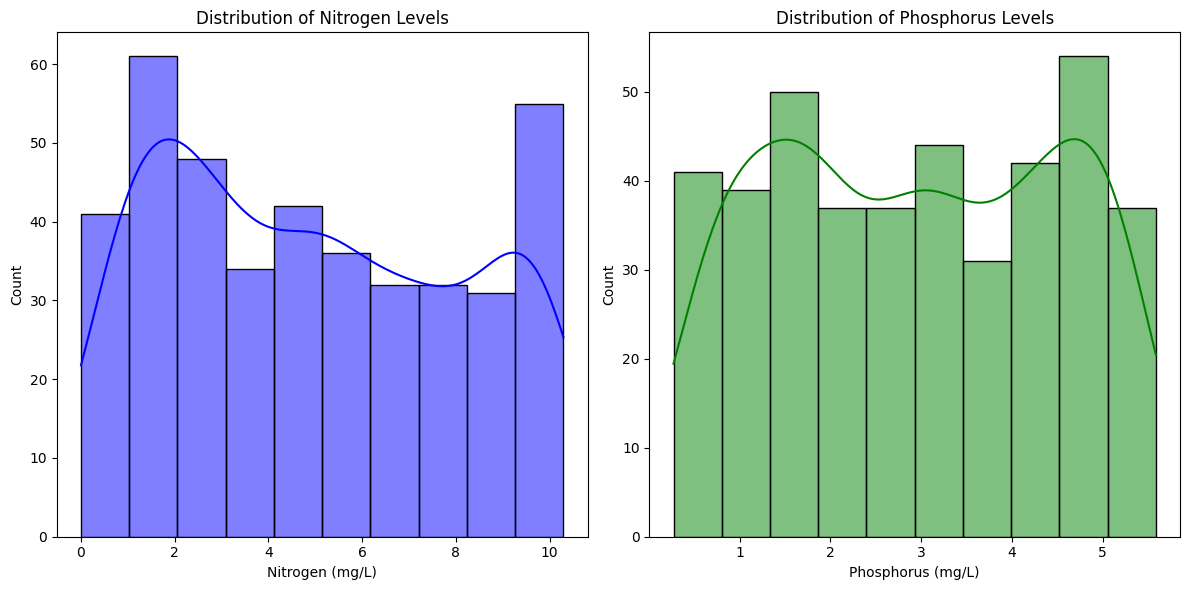

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.histplot(data=df, x='Nitrogen (mg/L)', kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribution of Nitrogen Levels')
axes[0].set_xlabel('Nitrogen (mg/L)')
axes[0].set_ylabel('Count')

sns.histplot(data=df, x='Phosphorus (mg/L)', kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribution of Phosphorus Levels')
axes[1].set_xlabel('Phosphorus (mg/L)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### A nitrogénszintek földrajzi eloszlása
Szórásdiagram, ahol a vízszintes tengely a hosszúsági, a függőleges tengely a szélességi koordináta, a pontok színe pedig a nitrogénszint (`coolwarm` paletta).

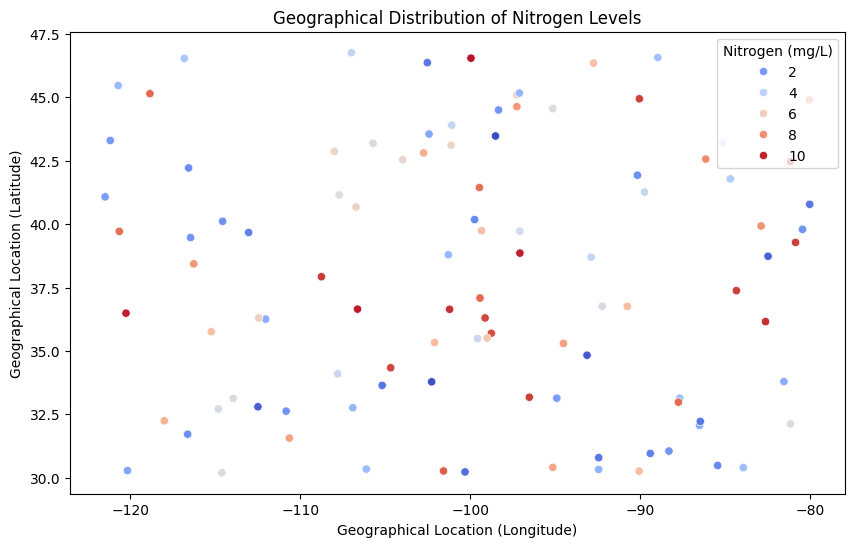

In [50]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Geographical Location (Longitude)',
    y='Geographical Location (Latitude)',
    hue='Nitrogen (mg/L)',
    palette='coolwarm'
)
plt.title('Geographical Distribution of Nitrogen Levels')
plt.xlabel('Geographical Location (Longitude)')
plt.ylabel('Geographical Location (Latitude)')
plt.legend(title='Nitrogen (mg/L)')
plt.show()

## 5. A foszforszintek interaktív térképen
Folium térkép a mérési helyekről: minden pont a GPS-koordinátáján jelenik meg, a színe a kerekített foszforszintet jelöli, kattintásra pedig a pontos érték látható.

In [51]:
from matplotlib import colors

max_P = round(df['Phosphorus (mg/L)'].max())
print("Maximális foszfor érték (kerekítve):", max_P)

levels = range(max_P + 1)
color_dict = dict(zip(levels, list(colors.cnames.values())[0:-1:10]))
print("Színkódok a különböző szintekhez:", color_dict)

center_lat = df['Geographical Location (Latitude)'].mean()
center_lon = df['Geographical Location (Longitude)'].mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=4)

for index, row in df.iterrows():
    p_level = int(round(row['Phosphorus (mg/L)']))

    folium.CircleMarker(
        location=[row['Geographical Location (Latitude)'], row['Geographical Location (Longitude)']],
        radius=5,
        color=color_dict.get(p_level, 'blue'),
        fill=True,
        fill_opacity=0.7,
        popup=f"Foszfor: {row['Phosphorus (mg/L)']:.2f} mg/L"
    ).add_to(m)


m

Maximális foszfor érték (kerekítve): 6
Színkódok a különböző szintekhez: {0: '#F0F8FF', 1: '#8A2BE2', 2: '#00FFFF', 3: '#FF8C00', 4: '#FF1493', 5: '#F8F8FF', 6: '#4B0082'}


## 6. A szennyvízrendszer állapota
Gyakorisági diagram (Seaborn `histplot`) arról, hogy a mérési helyeken milyen gyakori az egyes szennyvízrendszer-állapotok előfordulása.

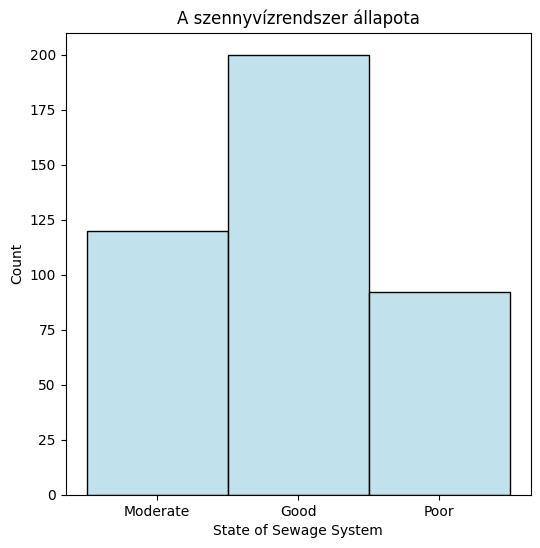

In [52]:
plt.figure(figsize=(6, 6))
sns.histplot(data=df, x='State of Sewage System', color='lightblue')
plt.title('A szennyvízrendszer állapota')
plt.xlabel('State of Sewage System')
plt.ylabel('Count')

plt.show()

## 7. Korrelációs elemzés

### Teljes szennyezettség (N+P)
Új oszlop a nitrogén- és foszforszint összegéből, amely a mérési helyeken mért teljes szennyezettséget mutatja.

In [53]:
df['N+P'] = df['Nitrogen (mg/L)'] + df['Phosphorus (mg/L)']
df[['Nitrogen (mg/L)','Phosphorus (mg/L)','N+P']].head()

,Nitrogen (mg/L),Phosphorus (mg/L),N+P
0,5.447159,4.634808,10.081967
1,9.087964,3.129082,12.217047
2,0.485658,4.545678,5.031337
3,2.666448,4.090627,6.757075
4,8.425540,1.247981,9.673521


### A szennyvízrendszer állapotának kódolása
A `State of Sewage System` szöveges értékeit `LabelEncoder`-rel számokká alakítjuk, majd az eredményt ellenőrizzük.

In [54]:
le = LabelEncoder()
df['State of Sewage System'] = le.fit_transform(df['State of Sewage System'])
df['State of Sewage System'].head()

,State of Sewage System
0,1
1,0
2,1
3,2
4,1


### Korrelációs mátrix
A numerikus oszlopok kiválasztása egy új DataFrame-be, a Pearson-korreláció kiszámítása, majd megjelenítés hőtérképen (3 tizedesjegyre kerekített együtthatókkal).

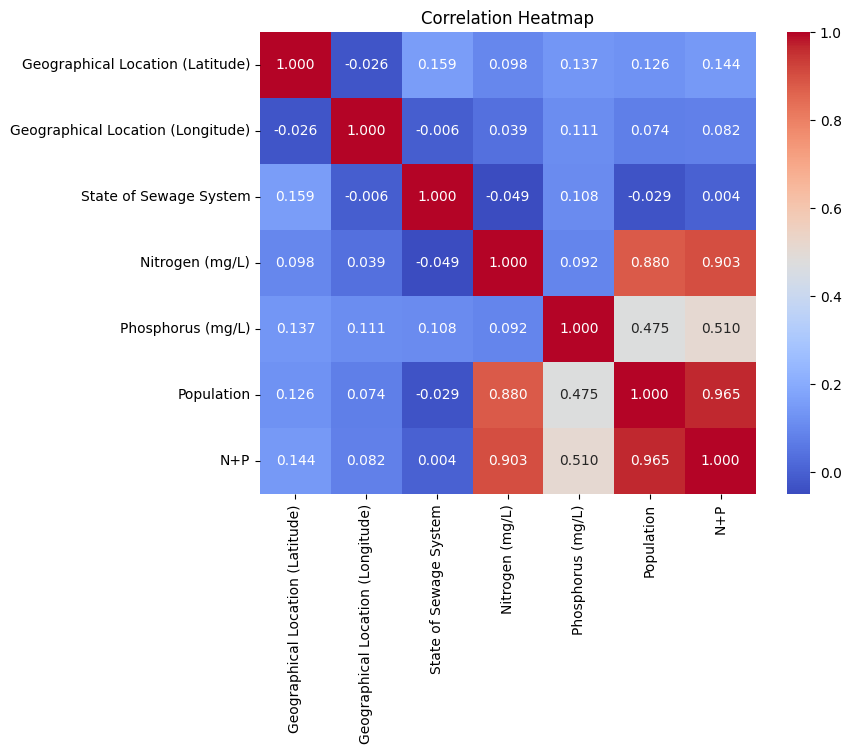

In [55]:
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr(method='pearson')
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## 8. Oszlopnevek rövidítése
A hosszú oszlopnevek rövidítése (`Lati`, `Long`, `SDate`, `N`, `P`, `SWS`), majd az `info()` kiírja, hogy az átnevezés sikerült.

In [56]:
df = df.rename(columns={
    'Geographical Location (Latitude)': 'Lati',
    'Geographical Location (Longitude)': 'Long',
    'Sampling Date': 'SDate',
    'Nitrogen (mg/L)': 'N',
    'Phosphorus (mg/L)': 'P',
    'State of Sewage System': 'SWS'
})

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Lati        412 non-null    float64       
 1   Long        412 non-null    float64       
 2   SWS         412 non-null    int64         
 3   SDate       412 non-null    datetime64[ns]
 4   N           412 non-null    float64       
 5   P           412 non-null    float64       
 6   Population  412 non-null    int64         
 7   N+P         412 non-null    float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 25.9 KB


## 9. Statisztikai jellemzők
A `describe()` kiírja az oszlopok alapstatisztikáit (átlag, szórás, minimum, maximum, kvartilisek).

In [57]:
df.describe()

,Lati,Long,SWS,SDate,N,P,Population,N+P
count,412.000000,412.000000,412.000000,412,412.000000,412.000000,4.120000e+02,412.000000
mean,37.928978,-99.910523,0.737864,2019-02-16 10:08:09.320388352,4.956458,2.941068,9.041799e+05,7.897526
min,30.198108,-121.476341,0.000000,2014-01-02 00:00:00,0.004284,0.272931,2.053480e+05,0.379070
25%,33.138387,-107.997678,0.000000,2016-12-24 18:00:00,2.096088,1.593510,6.752212e+05,4.725642
50%,37.926803,-99.464055,1.000000,2018-12-08 12:00:00,4.821583,2.951642,8.774995e+05,7.935702
75%,42.542049,-90.071769,1.000000,2021-07-02 06:00:00,7.575510,4.327313,1.184369e+06,10.852442
max,46.759853,-80.039258,2.000000,2023-12-25 00:00:00,10.294660,5.586694,1.544160e+06,15.538928
std,5.088459,11.689830,0.800987,NaN,3.097449,1.544422,3.163950e+05,3.585622


## 10. Minőségi kategóriák (Q)
Az `apply()` függvénnyel új `Q` oszlopot hozunk létre az N+P érték alapján: 1, ha kisebb 4-nél; 3, ha nagyobb 10-nél; egyébként 2.

In [58]:
def qhataroz(ertek):
    if ertek < 4:
        return 1
    elif ertek > 10:
        return 3
    else:
        return 2
df['Q'] = df['N+P'].apply(qhataroz)
df[['N+P', 'Q']].head(10)

,N+P,Q
0,10.081967,3
1,12.217047,3
2,5.031337,2
3,6.757075,2
4,9.673521,2
5,15.419639,3
6,12.502459,3
7,8.660673,2
8,3.189861,1
9,13.641780,3


## 11. A kategóriák gyakorisága
A `Q` értékek szerinti csoportosítás, majd a csoportok méretének kiírása.

In [59]:
print(df.groupby('Q').size())

Q
1     77
2    193
3    142
dtype: int64


## 12. A minőségi kategóriák földrajzi eloszlása
Szórásdiagram a mérési helyekről, ahol a pont színe a `Q` kategóriát jelzi (`coolwarm` paletta).

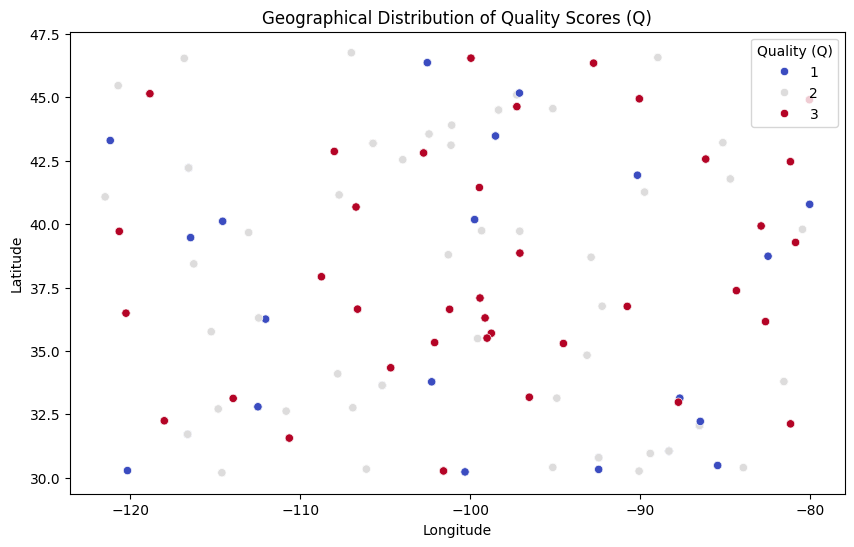

In [60]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Long', y='Lati', hue='Q', palette='coolwarm')

plt.title('Geographical Distribution of Quality Scores (Q)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Quality (Q)')
plt.show()

# Gépi tanulási modellek

## 13. Adatok előkészítése a döntési fához
A dátum oszlop nélküli új DataFrame (`df_ml`) létrehozása, majd az adatok szétválasztása független változókra (`x`) és a célváltozóra (`y`: a szennyvízrendszer állapota, `SWS`).

In [61]:
df_ml = df.drop(columns=['SDate'])
print(df_ml.head())
x = df_ml.drop(columns=['SWS'])
y = df_ml['SWS']

        Lati        Long  SWS         N         P  Population        N+P  Q
0  42.867278 -107.997678    1  5.447159  4.634808      923253  10.081967  3
1  34.337029 -104.681197    0  9.087964  3.129082     1196631  12.217047  3
2  34.831615  -93.134004    1  0.485658  4.545678      781628   5.031337  2
3  45.463162 -120.709056    2  2.666448  4.090627      855275   6.757075  2
4  41.444474  -99.464055    1  8.425540  1.247981     1019428   9.673521  2


## 14. Döntési fa: felosztás, tanítás, vizualizáció
Az adatok véletlenszerű felosztása tanító és teszt halmazra (80/20), a döntési fa betanítása (maximális mélység: 3), majd a fa kirajzolása.

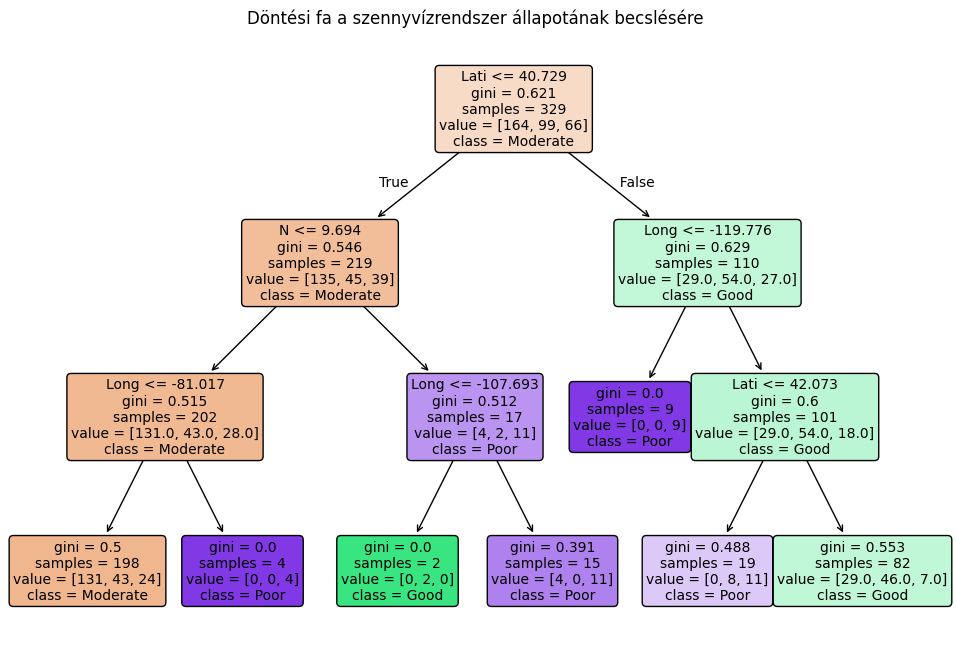

In [62]:
from sklearn.tree import plot_tree

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(x_train, y_train)

plt.figure(figsize=(12, 8))
plot_tree(model,
          feature_names=x.columns,
          class_names=['Moderate', 'Good', 'Poor'],
          filled=True,
          rounded=True,
          fontsize=10)

plt.title("Döntési fa a szennyvízrendszer állapotának becslésére")
plt.show()

## 15. A döntési fa értékelése
Predikció a teszthalmazon, majd a pontosság, az osztályozási riport és a konfúziós mátrix kiírása.

A modell pontossága: 53.01%
------------------------------
Osztályozási riport:
              precision    recall  f1-score   support

    Moderate       0.48      0.56      0.51        36
        Good       0.42      0.52      0.47        21
        Poor       0.87      0.50      0.63        26

    accuracy                           0.53        83
   macro avg       0.59      0.53      0.54        83
weighted avg       0.59      0.53      0.54        83

------------------------------


<Figure size 800x600 with 0 Axes>

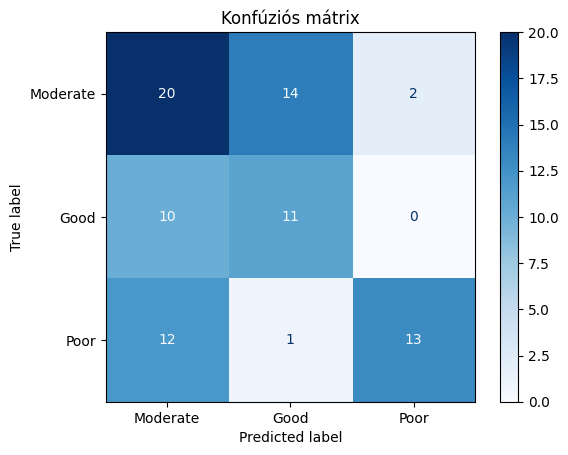

In [63]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"A modell pontossága: {accuracy:.2%}")
print("-" * 30)

print("Osztályozási riport:")
print(classification_report(y_test, y_pred, target_names=['Moderate', 'Good', 'Poor']))
print("-" * 30)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Moderate', 'Good', 'Poor'])

plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title("Konfúziós mátrix")
plt.show()

## 16. Lineáris regresszió: népesség és szennyezettség
A népesség (`Population`) és a teljes szennyezettség (`N+P`) kapcsolatának vizsgálata. Az adatok 80/20 arányú felosztása után a modell betanítása, az R² érték kiírása, majd a teszt adatok és a regressziós egyenes ábrázolása.

R2 érték (mennyire illeszkedik a vonal): 0.9196


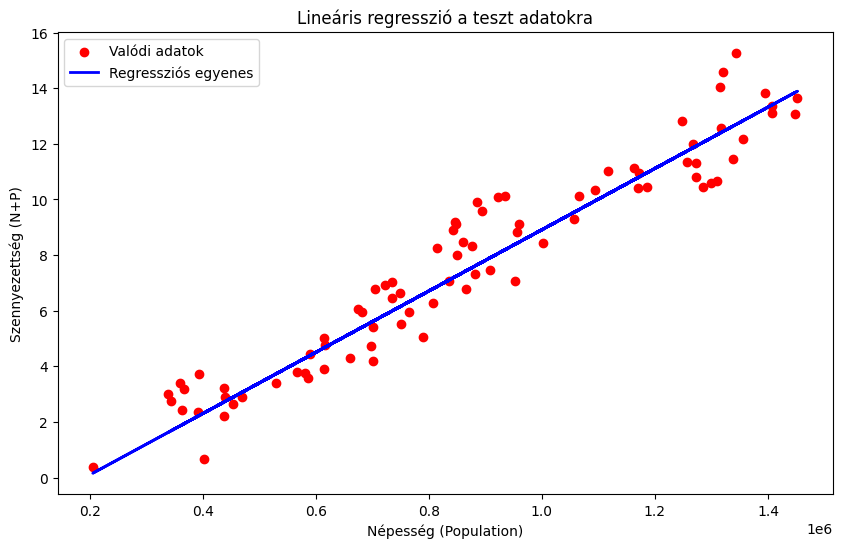

In [64]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_reg = df[['Population']]
y_reg = df['N+P']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_model = LinearRegression()
reg_model.fit(X_train_reg, y_train_reg)

y_pred_reg = reg_model.predict(X_test_reg)

print(f"R2 érték (mennyire illeszkedik a vonal): {r2_score(y_test_reg, y_pred_reg):.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(X_test_reg, y_test_reg, color='red', label='Valódi adatok')
plt.plot(X_test_reg, y_pred_reg, color='blue', linewidth=2, label='Regressziós egyenes')

plt.title('Lineáris regresszió a teszt adatokra')
plt.xlabel('Népesség (Population)')
plt.ylabel('Szennyezettség (N+P)')
plt.legend()
plt.show()

## 17. A regressziós modell értékelése
Az első öt predikció összehasonlítása az első öt valós teszt értékkel, valamint a modell pontosságának (R²) kiírása.

In [65]:
y_pred_reg = reg_model.predict(X_test_reg)

print("Az első 5 predikció (tipp):")
print(y_pred_reg[:5])

print("\nAz első 5 valós y teszt érték (valós érték):")
print(y_test_reg.values[:5])

accuracy_reg = reg_model.score(X_test_reg, y_test_reg)
print(f"\nA betanított modellünk pontossága (R2): {accuracy_reg:.4f}")

Az első 5 predikció (tipp):
[5.41130086 7.64173826 7.10500045 4.66348416 5.17507805]

Az első 5 valós y teszt érték (valós érték):
[5.94757339 9.90639491 7.06354842 5.00048622 4.28705414]

A betanított modellünk pontossága (R2): 0.9196
